# Tarea 2 · Parte 2 — Evaluación, extracción estructurada y comparación de modelos

1. **Muestra de evaluación:** 10 documentos y 10 clips del corpus de la Parte 1, con transcripción manual.
2. **Modelos:** línea base (PaddleOCR por defecto; faster-whisper `small` en CPU) y alternativas sobre las mismas
   muestras (EasyOCR y Gemini con visión; Parakeet TDT 0.6B v3 y Whisper large-v3-turbo).
3. **Métricas:** CER y WER con la misma normalización para todos, y latencia (factor de tiempo real).
4. **Casos difíciles:** manuscritos, audio de calle y audio con música.
5. **Extracción estructurada** con un LLM y **auditoría humana** de 20 casos.
6. **Comparativa y decisión.**

Las configuraciones de todos los modelos se fijaron en la sección 2 antes de calcular cualquier métrica y no se
cambiaron después.

## 0 · Preparación

In [1]:
import json
import logging
import os
import re
import time
import warnings
from datetime import date
from pathlib import Path

os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"
warnings.filterwarnings("ignore")
logging.disable(logging.INFO)   # sin los mensajes informativos de kaleido, Hugging Face y faster-whisper
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

import jiwer
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
from dotenv import load_dotenv

import herramientas
import voz

pio.renderers.default = "plotly_mimetype+png"
pd.set_option("display.max_colwidth", 110)
load_dotenv(".env")   # lee GEMINI_API_KEY del archivo .env (no se sube a GitHub)

DATOS, RAW = Path("datos"), Path("datos/raw")
REF, HIP = RAW / "referencias", RAW / "hipotesis"
REF.mkdir(exist_ok=True)
HIP.mkdir(exist_ok=True)

documentos = pd.read_csv(DATOS / "documentos.csv", keep_default_na=False)
transcripciones = pd.read_csv(DATOS / "transcripciones.csv", keep_default_na=False)
ocr_crudo = pd.read_csv(RAW / "ocr_crudo.csv", keep_default_na=False)
asr_crudo = pd.read_csv(RAW / "asr_crudo.csv", keep_default_na=False)
REEMPLAZOS = herramientas.cargar_reemplazos()


def publicable(texto):
    "Texto seudonimizado: es lo único que se muestra en este notebook o se guarda fuera de datos/raw/."
    return herramientas.seudonimizar(str(texto), REEMPLAZOS)[0]


print(f"Corpus: {len(documentos)} documentos y {len(transcripciones)} clips "
      f"({transcripciones['duracion_seg'].sum() / 60:.1f} min)")

Corpus: 31 documentos y 22 clips (52.3 min)


## 1 · Muestra de evaluación

Se eligieron 10 documentos (3 impresos, 3 fotos y 4 manuscritos) y 10 clips de cinco fuentes y condiciones de
grabación distintas: entrevistas en fiestas de Áncash (una con banda de música de fondo), testimonios grabados en
San Martín y en Lima, y entrevistas de estudiantes en la calle con varios hablantes. El criterio fue cubrir todos
los tipos con textos y clips que se pudieran transcribir a mano, y no usar ningún archivo que aparezca en las
clases. La lista se fijó antes de correr cualquier modelo alternativo. En los manuscritos, las palabras que no se
pudieron leer a mano se omitieron en la referencia.

In [2]:
EVAL_DOCS = ["carta_presidencia_1956", "almanaque_cascabel_1873", "constitucion_1860",      # impresos
             "placa_quinones", "placa_grau_miraflores", "placa_nazarenas",                   # fotos
             "carta_vallejo_1917", "carta_pierola_1897", "carta_gamarra_1822", "tarjeta_circulacion_1921"]   # manuscritos
EVAL_CLIPS = ["fiesta_chuyas", "fiesta_pomabamba", "fiesta_shuyas", "san_martin_2", "san_martin_3",
              "san_martin_4", "salas_3", "salas_5", "unmsm_2", "unmsm_3"]

muestra_docs = (ocr_crudo[ocr_crudo["clave"].isin(EVAL_DOCS)]
                .merge(documentos[["id", "archivo", "url_imagen"]], on="id").reset_index(drop=True))
muestra_clips = (asr_crudo[asr_crudo["clave"].isin(EVAL_CLIPS)]
                 .merge(transcripciones[["id", "archivo_audio", "duracion_seg"]], on="id").reset_index(drop=True))
assert len(muestra_docs) == 10 and len(muestra_clips) == 10
assert set(muestra_docs["tipo"]) == {"impreso", "foto", "manuscrito"}

print(muestra_docs["tipo"].value_counts().to_string(), "\n")
print(muestra_clips["condicion"].value_counts().to_string())
print(f"\nAudio de la muestra: {muestra_clips['duracion_seg'].sum() / 60:.1f} min")

tipo
manuscrito    4
impreso       3
foto          3 

condicion
testimonio    5
fiesta        3
entrevista    2

Audio de la muestra: 11.6 min


### Transcripciones manuales (`texto_referencia`)

Cada referencia se escribió a mano en `datos/raw/referencias/<id>.txt`, mirando la imagen o escuchando el audio,
**sin mirar la salida de ningún modelo**. Reglas:

- **Documentos:** todo el texto visible, en orden de lectura (de arriba abajo y de izquierda a derecha; si hay
  columnas, una columna completa tras otra). Se respeta la ortografía original («quando», «á este»); no se
  corrige ni se moderniza. Las palabras que ni una persona puede leer se omiten.
- **Audios:** todas las palabras dichas por todos los hablantes, incluidas las repeticiones; sin muletillas («eh»,
  «mmm») ni marcas de hablante. Lo que no se entiende (por la música o el ruido) se omite.

Las referencias tienen nombres reales, por eso quedan en `datos/raw/`. A los CSV publicados va su versión
seudonimizada.

In [3]:
ids_eval = list(muestra_docs["id"]) + list(muestra_clips["id"])
for i in ids_eval:
    archivo = REF / f"{i}.txt"
    if not archivo.exists():
        archivo.write_text("", encoding="utf-8")

referencias = {i: (REF / f"{i}.txt").read_text(encoding="utf-8").strip() for i in ids_eval}
hoja = pd.concat([muestra_docs[["id", "clave", "tipo", "archivo"]],
                  muestra_clips[["id", "clave", "condicion", "archivo_audio"]]
                  .rename(columns={"condicion": "tipo", "archivo_audio": "archivo"})])
hoja["caracteres_referencia"] = hoja["id"].map(lambda i: len(referencias[i]))
faltan = hoja.loc[hoja["caracteres_referencia"] == 0, "id"].tolist()
display(hoja)
assert not faltan, f"Faltan {len(faltan)} transcripciones manuales en datos/raw/referencias/: {faltan}"

,id,clave,tipo,archivo,caracteres_referencia
0,doc_005,almanaque_cascabel_1873,impreso,datos/raw/documentos/originales/doc_005.jpg,94
1,doc_007,carta_presidencia_1956,impreso,datos/raw/documentos/originales/doc_007.jpg,447
2,doc_009,constitucion_1860,impreso,datos/raw/documentos/originales/doc_009.jpg,138
3,doc_017,placa_grau_miraflores,foto,datos/raw/documentos/originales/doc_017.jpg,131
4,doc_018,placa_nazarenas,foto,datos/raw/documentos/originales/doc_018.jpg,88
5,doc_019,placa_quinones,foto,datos/raw/documentos/originales/doc_019.jpg,153
6,doc_022,carta_vallejo_1917,manuscrito,datos/raw/documentos/originales/doc_022.jpg,765
7,doc_028,tarjeta_circulacion_1921,manuscrito,datos/raw/documentos/originales/doc_028.jpg,260
8,doc_029,carta_gamarra_1822,manuscrito,datos/raw/documentos/originales/doc_029.jpg,487
9,doc_031,carta_pierola_1897,manuscrito,datos/raw/documentos/originales/doc_031.jpg,393


## 2 · Modelos y configuraciones (fijadas antes de medir)

**Documentos**

| Modelo | Por qué | Configuración |
|---|---|---|
| PaddleOCR PP-OCRv6 (base) | OCR clásico de la Sesión 10 | modelos por defecto (PP-OCRv6_medium), motor PyTorch en CPU, sin orientación ni enderezado (igual que en la Parte 1) |
| EasyOCR 1.7 | otra familia de OCR clásico (detector CRAFT + reconocedor CRNN), se instala con pip | `Reader(["es"])`, CPU, una línea por detección |
| Gemini 3.5 Flash con visión | modelo de visión-lenguaje: debería leer mejor la letra a mano, pero puede inventar | temperatura 0 y una instrucción fija de transcripción literal |

**Audio**

| Modelo | Por qué | Configuración |
|---|---|---|
| faster-whisper `small` (base) | línea base pedida, en CPU | int8, VAD on, beam 5, `es`, sin condicionar en el texto previo (igual que en la Parte 1) |
| Parakeet TDT 0.6B v3 (NVIDIA) | otra arquitectura (transductor, no genera texto libre): no debería alucinar en silencios | `voz.Transcriptor("parakeet-v3")`, CPU, cortes por VAD de máximo 12 s |
| Whisper large-v3-turbo (faster-whisper) | la versión grande de la misma familia, para medir cuánto se gana con más parámetros | la misma configuración que la base |

La primera pasada de cada modelo local se hace sobre un archivo que no está en la muestra, para que la carga y el
calentamiento no cuenten en la latencia. Cada salida se guarda en `datos/raw/hipotesis/` y no se recalcula.

In [4]:
from faster_whisper import WhisperModel
from google import genai
from google.genai import types
from paddleocr import PaddleOCR

import easyocr
import transformers

transformers.logging.disable_progress_bar()

MODELO_LLM = "gemini-3.5-flash"
cliente = genai.Client()


def pedir_a_gemini(**kwargs):
    "Llama a Gemini con reintentos si el servicio está saturado; se detiene con un mensaje claro si se acabó la cuota del día."
    for intento in range(1, 4):
        try:
            return cliente.models.generate_content(**kwargs)
        except Exception as error:
            if "RESOURCE_EXHAUSTED" in str(error) and "per day" in str(error):
                raise RuntimeError("Se acabó la cuota diaria gratuita de Gemini. Lo ya obtenido quedó guardado: "
                                   "vuelve a ejecutar mañana y solo se pedirá lo que falta.") from None
            if intento == 3:
                raise
            print(f"   Gemini no respondió ({str(error)[:60]}…); reintento en {30 * intento} s")
            time.sleep(30 * intento)


paddle = PaddleOCR(engine="transformers", device="cpu", use_doc_orientation_classify=False, use_doc_unwarping=False, use_textline_orientation=False)
lector = easyocr.Reader(["es"], gpu=False, verbose=False)

PROMPT_OCR = (
    "Transcribe todo el texto visible en esta imagen, tal como está escrito: no corrijas ni modernices la "
    "ortografía. Sigue el orden de lectura (de arriba abajo y de izquierda a derecha; si hay columnas, una columna "
    "completa después de la otra). Devuelve solo el texto, sin comentarios ni formato Markdown. Si una palabra no "
    "se puede leer, omítela."
)


def ocr_paddle(ruta):
    return "\n".join(paddle.predict(str(ruta))[0]["rec_texts"])


def ocr_easyocr(ruta):
    return "\n".join(lector.readtext(str(ruta), detail=0, paragraph=False))


def ocr_gemini(ruta):
    tipo = "image/png" if str(ruta).lower().endswith(".png") else "image/jpeg"
    imagen = types.Part.from_bytes(data=Path(ruta).read_bytes(), mime_type=tipo)
    r = pedir_a_gemini(model=MODELO_LLM, contents=[imagen, PROMPT_OCR], config=types.GenerateContentConfig(temperature=0))
    return (r.text or "").strip()


MODELOS_OCR = {
    "PaddleOCR PP-OCRv6 (base)": ocr_paddle,
    "EasyOCR 1.7": ocr_easyocr,
    "Gemini 3.5 Flash (visión)": ocr_gemini,
}

In [5]:
CONFIG_ASR = dict(language="es", beam_size=5, vad_filter=True, condition_on_previous_text=False,
                  vad_parameters={"min_silence_duration_ms": 300})
whisper_small = WhisperModel("small", device="cpu", compute_type="int8", cpu_threads=min(8, os.cpu_count() or 4))
whisper_turbo = WhisperModel(voz.MODELOS["faster-whisper"]["hf"], device="cpu", compute_type="int8",
                             cpu_threads=min(8, os.cpu_count() or 4))
parakeet = voz.Transcriptor("parakeet-v3", device="cpu")


def asr_small(audio):
    return " ".join(s.text.strip() for s in whisper_small.transcribe(audio, **CONFIG_ASR)[0])


def asr_turbo(audio):
    return " ".join(s.text.strip() for s in whisper_turbo.transcribe(audio, **CONFIG_ASR)[0])


def asr_parakeet(audio):
    return " ".join(s.texto for s in parakeet.segmentos(audio))


MODELOS_ASR = {
    "faster-whisper small (base)": asr_small,
    "Parakeet TDT 0.6B v3": asr_parakeet,
    "Whisper large-v3-turbo": asr_turbo,
}

### Correr todos los modelos sobre las mismas muestras

In [6]:
def correr(modelos, muestra, columna_archivo, preparar, calentar_con):
    "Corre cada modelo sobre cada archivo de la muestra; guarda texto y segundos en datos/raw/hipotesis/."
    filas = []
    for nombre, modelo in modelos.items():
        carpeta = HIP / re.sub(r"\W+", "_", nombre).strip("_")
        carpeta.mkdir(exist_ok=True)
        calentado = False
        for fila in muestra.itertuples():
            cache = carpeta / f"{fila.id}.json"
            if not cache.exists():
                if not calentado and "Gemini" not in nombre:
                    modelo(preparar(calentar_con))
                    calentado = True
                entrada = preparar(getattr(fila, columna_archivo))
                t0 = time.perf_counter()
                texto = modelo(entrada)
                cache.write_text(json.dumps({"texto": texto, "segundos": time.perf_counter() - t0}, ensure_ascii=False),
                                 encoding="utf-8")
                if "Gemini" in nombre:
                    time.sleep(4)   # capa gratuita: pocas solicitudes por minuto (fuera del cronómetro)
            guardado = json.loads(cache.read_text(encoding="utf-8"))
            filas.append({"id": fila.id, "modelo": nombre, "hipotesis": guardado["texto"], "segundos": guardado["segundos"]})
        print(f"{nombre}: listo")
    return pd.DataFrame(filas)


fuera_docs = documentos.loc[~documentos["id"].isin(muestra_docs["id"]), "archivo"].iloc[0]
fuera_clip = transcripciones.loc[~transcripciones["id"].isin(muestra_clips["id"]), "archivo_audio"].iloc[0]

salidas_ocr = correr(MODELOS_OCR, muestra_docs, "archivo", lambda ruta: ruta, fuera_docs)
salidas_asr = correr(MODELOS_ASR, muestra_clips, "archivo_audio", voz.cargar_audio, fuera_clip)

PaddleOCR PP-OCRv6 (base): listo
EasyOCR 1.7: listo
Gemini 3.5 Flash (visión): listo
faster-whisper small (base): listo
Parakeet TDT 0.6B v3: listo
Whisper large-v3-turbo: listo


## 3 · Métricas sobre la muestra

Referencias e hipótesis pasan por la misma normalización (`herramientas.para_medir`): minúsculas, sin puntuación,
sin saltos de línea y sin marcas como `[HABLANTE_1]`, que no son palabras dichas. Las tildes se mantienen. El
CER y el WER globales suman los errores de los 10 casos y los dividen entre el total de caracteres o palabras de
las referencias (así un documento corto no pesa lo mismo que uno largo).

In [7]:
def medir(salidas, muestra, metrica, columna_grupo):
    t = salidas.merge(muestra[["id", "clave", columna_grupo]], on="id")
    t["referencia"] = t["id"].map(referencias)
    ref = t["referencia"].map(herramientas.para_medir)
    hip = t["hipotesis"].map(herramientas.para_medir).replace("", "∅")
    t["error"] = [metrica(r, h) for r, h in zip(ref, hip)]
    t["edits"] = t["error"] * ref.map(len if metrica is jiwer.cer else lambda x: len(x.split()))
    t["largo_ref"] = ref.map(len if metrica is jiwer.cer else lambda x: len(x.split()))
    return t.rename(columns={columna_grupo: "grupo"})


ev_ocr = medir(salidas_ocr, muestra_docs, jiwer.cer, "tipo")
ev_asr = medir(salidas_asr, muestra_clips.rename(columns={"condicion": "tipo"}), jiwer.wer, "tipo")
ev_asr = ev_asr.merge(muestra_clips[["id", "duracion_seg"]], on="id")
ev_asr["rtf"] = ev_asr["segundos"] / ev_asr["duracion_seg"]


def resumen(ev, nombre_metrica):
    g = ev.groupby("modelo")
    tabla = pd.DataFrame({nombre_metrica: g["edits"].sum() / g["largo_ref"].sum(),
                          "segundos_por_caso": g["segundos"].mean()})
    if "rtf" in ev:
        tabla["factor_tiempo_real"] = g["segundos"].sum() / g["duracion_seg"].sum()
    return tabla.sort_values(nombre_metrica)


cer_global = resumen(ev_ocr, "CER")
wer_global = resumen(ev_asr, "WER")
display(cer_global.round(3))
display(wer_global.round(3))

,CER,segundos_por_caso
modelo,,
Gemini 3.5 Flash (visión),0.412,54.759
PaddleOCR PP-OCRv6 (base),0.421,9.908
EasyOCR 1.7,0.659,10.977


,WER,segundos_por_caso,factor_tiempo_real
modelo,,,
Whisper large-v3-turbo,0.193,34.349,0.495
faster-whisper small (base),0.264,12.599,0.182
Parakeet TDT 0.6B v3,0.338,210.336,3.034


In [8]:
cer_tipo = (ev_ocr.groupby(["modelo", "grupo"])[["edits", "largo_ref"]].sum()
            .eval("CER = edits / largo_ref")["CER"].unstack().round(3)[["impreso", "foto", "manuscrito"]])
wer_condicion = (ev_asr.groupby(["modelo", "grupo"])[["edits", "largo_ref"]].sum()
                 .eval("WER = edits / largo_ref")["WER"].unstack().round(3))
display(cer_tipo)
display(wer_condicion)

grupo,impreso,foto,manuscrito
modelo,,,
EasyOCR 1.7,0.714,0.178,0.736
Gemini 3.5 Flash (visión),0.822,0.331,0.279
PaddleOCR PP-OCRv6 (base),0.534,0.101,0.445


grupo,entrevista,fiesta,testimonio
modelo,,,
Parakeet TDT 0.6B v3,0.246,0.616,0.154
Whisper large-v3-turbo,0.038,0.490,0.028
faster-whisper small (base),0.137,0.543,0.098


In [9]:
base_ocr, base_asr = "PaddleOCR PP-OCRv6 (base)", "faster-whisper small (base)"
print(f"LÍNEA BASE · CER de PaddleOCR sobre los 10 documentos: {cer_global.loc[base_ocr, 'CER']:.3f}")
print(f"LÍNEA BASE · WER de faster-whisper small sobre los 10 clips: {wer_global.loc[base_asr, 'WER']:.3f} "
      f"(factor de tiempo real {wer_global.loc[base_asr, 'factor_tiempo_real']:.2f})")

LÍNEA BASE · CER de PaddleOCR sobre los 10 documentos: 0.421
LÍNEA BASE · WER de faster-whisper small sobre los 10 clips: 0.264 (factor de tiempo real 0.18)


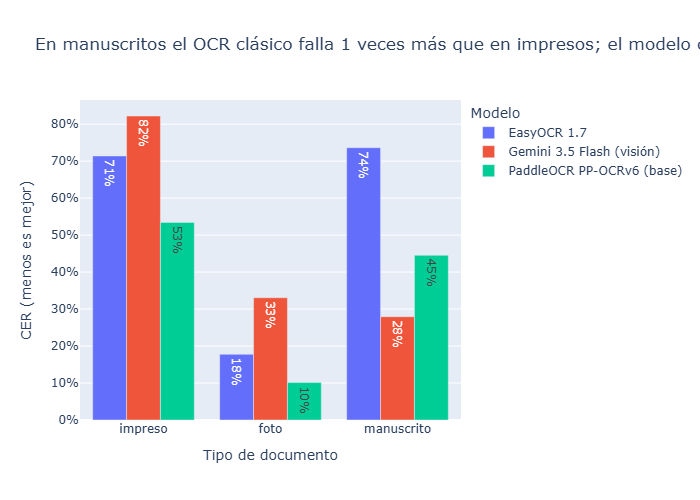

In [10]:
fig = px.bar(ev_ocr.groupby(["modelo", "grupo"])[["edits", "largo_ref"]].sum().eval("CER = edits / largo_ref").reset_index(),
             x="grupo", y="CER", color="modelo", barmode="group", text_auto=".0%",
             category_orders={"grupo": ["impreso", "foto", "manuscrito"]},
             labels={"grupo": "Tipo de documento", "CER": "CER (menos es mejor)", "modelo": "Modelo"},
             title=f"En manuscritos el OCR clásico falla {cer_tipo.loc[base_ocr, 'manuscrito'] / max(cer_tipo.loc[base_ocr, 'impreso'], 1e-9):.0f} "
                   f"veces más que en impresos; el modelo con visión reduce esa brecha")
fig.update_yaxes(tickformat=".0%")
fig.show()

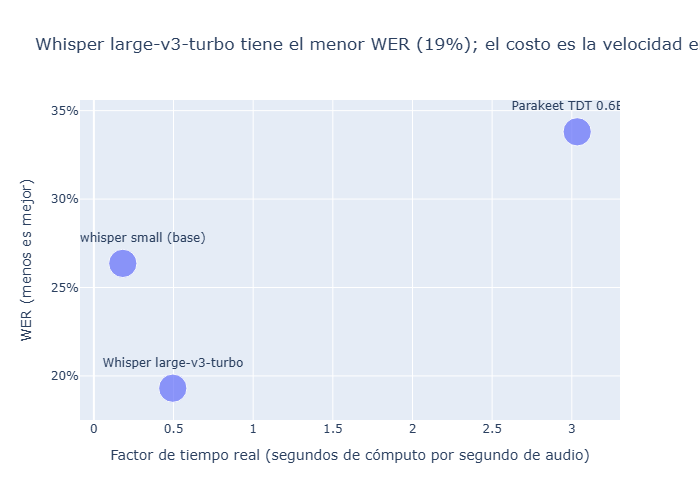

In [11]:
mejor_asr = wer_global.index[0]
fig = px.scatter(wer_global.reset_index(), x="factor_tiempo_real", y="WER", text="modelo", size=[18] * len(wer_global),
                 labels={"factor_tiempo_real": "Factor de tiempo real (segundos de cómputo por segundo de audio)",
                         "WER": "WER (menos es mejor)"},
                 title=f"{mejor_asr} tiene el menor WER ({wer_global.loc[mejor_asr, 'WER']:.0%}); "
                       f"el costo es la velocidad en CPU")
fig.update_traces(textposition="top center")
fig.update_yaxes(tickformat=".0%")
fig.show()

## 4 · Casos difíciles

Para cada caso: el error de cada modelo y el comienzo de la referencia frente a lo que leyó o escuchó cada uno
(textos seudonimizados).

In [12]:
def comparar(ev, clave, largo=260):
    caso = ev[ev["clave"] == clave]
    print(f"━━ {clave} ({caso['grupo'].iloc[0]})")
    print(f"   REFERENCIA: {publicable(caso['referencia'].iloc[0]).replace(chr(10), ' ')[:largo]}")
    for fila in caso.itertuples():
        print(f"   {fila.modelo} [{fila.error:.0%}]: {publicable(fila.hipotesis).replace(chr(10), ' ')[:largo]}")
    print()


peor_manuscrito = ev_ocr[(ev_ocr["grupo"] == "manuscrito") & (ev_ocr["modelo"] == base_ocr)].nlargest(1, "error")["clave"].iloc[0]
for clave in [peor_manuscrito, "placa_quinones"]:
    comparar(ev_ocr, clave)

━━ carta_gamarra_1822 (manuscrito)
   REFERENCIA: Señor D. Domingo Tristán  Guallgua, marzo 2 de 1822.   Mi mejor amigo: incluyo a V. el  que se han traído desde la  de  y el oficio del Comandante González  . Ya  enterado de considerar las ventajas que vamos a  perder si paralizamos nuestros movimientos.  un 
   PaddleOCR PP-OCRv6 (base) [60%]: D D Pamingo Fristan VeralquaOnar2o 2de1822 ooriginalaherlo han traide de la a ra de Carabele y el oficio del Comani. Somrales ge enlenao ed coniverr las ventalas qvamon à pever si paxalicamor murtaa movimientor. Judo un momento g virtor tantor inidentu con Ven
   EasyOCR 1.7 [87%]: Jonsf Ua;e {faUca 29e/8*22 Vea Oo 47 2 72ue = 2/ %* vaje P2 & Ya "0 S< Czabear 07446 e,2.& (nza&_ 1? 7  € en8) Cof eax ca/ vazor 4 Yrnez 4 paxaliamor ?un*a 700v8n222 22, 241 720710775 "vig ~)eze& 022 ~0caza 71244/% 4c 4eta ?784 ' 4, eefexc 2uM 44 /incenunaa 27
   Gemini 3.5 Flash (visión) [54%]: Cor.l D Domingo Tristan Guallgua Marzo 2. de 1822  Mi mejor Amigo. incluy

In [13]:
for clave in ["fiesta_shuyas", "unmsm_3"]:
    comparar(ev_asr, clave)

━━ fiesta_shuyas (fiesta)
   REFERENCIA: ¿Cómo se llama usted? [PERSONA_39]. Ok, usted pertenece al pueblo de Chuyas. Chuyas, ¿verdad? Sí, es Chuyas. ¿Usted pertenece al pueblo? Sí. ¿Y cómo está viviendo este momento? Bien, lo estoy recordando. Pues sí, la imagen se celebra ya en la sierra en Chuyas,
   faster-whisper small (base) [92%]: ¿Como se vive en ese momento el dolor? Pues sí, la imagen se celebra ya en la sierra en Chuyas, pero acá ya bueno, para no creer... ¿Sólo de venir haciam...
   Parakeet TDT 0.6B v3 [90%]: Yeah. Y usted pertenece al pueblo. ¿Y cómo está viviendo este momento? Sí, la imagen se celebra allá en la sierra en Chuyas, pero acá... Bueno pero no
   Whisper large-v3-turbo [89%]: ¿Qué se llama? Chuyas, ¿verdad? Sí, es Chuyas. ¿Usted pertenece a Pueblo? Sí, sí. ¿Cómo está viviendo este momento? Pues en sí la imagen se celebra allá en Glacier, en Chuyas, pero acá ya bueno...

━━ unmsm_3 (entrevista)
   REFERENCIA: Buenas noches, soy [PERSONA_4], estudiante de San M

**Alucinaciones.** En los clips de la muestra, ¿algún modelo produjo bastante más texto que la referencia? Una
hipótesis mucho más larga que la referencia suele ser texto inventado en silencios o en la música.

In [14]:
ev_asr["palabras_hip"] = ev_asr["hipotesis"].map(lambda t: len(herramientas.para_medir(t).split()))
ev_asr["exceso"] = ev_asr["palabras_hip"] / ev_asr["largo_ref"]
ev_asr.pivot(index="clave", columns="modelo", values="exceso").round(2)

modelo,Parakeet TDT 0.6B v3,Whisper large-v3-turbo,faster-whisper small (base)
clave,,,
fiesta_chuyas,1.00,0.99,1.00
fiesta_pomabamba,0.65,0.92,0.95
fiesta_shuyas,0.11,0.14,0.12
salas_3,1.07,0.99,0.97
salas_5,1.07,1.02,1.01
san_martin_2,1.12,1.00,1.01
san_martin_3,1.14,0.97,1.03
san_martin_4,1.11,0.99,0.99
unmsm_2,1.26,1.00,1.05


## 5 · Extracción estructurada con un LLM

Gemini 3.5 Flash Lite recibe los textos **ya seudonimizados** (OCR o ASR) y devuelve un JSON con un esquema fijo.
La instrucción le pide usar `null` para lo que no aparece y no completar con conocimiento propio. Temperatura 0.

La capa gratuita de Gemini permite unas 20 solicitudes al día por modelo, así que los textos se envían en lotes de
8 (unas 7 solicitudes para todo el corpus) y con un modelo distinto al de la lectura de imágenes, que tiene su
propia cuota. Cada respuesta se guarda en `datos/raw/llm/`: si la cuota se acaba, basta con volver a ejecutar al
día siguiente y solo se piden los textos que faltan.

In [15]:
from pydantic import BaseModel, Field

MODELO_EXTRACCION = "gemini-3.5-flash-lite"


class Extraccion(BaseModel):
    id: str = Field(description="el id del texto, copiado tal cual")
    modalidad: str = Field(description="'documento' o 'audio'")
    tema: str = Field(description="tema principal en pocas palabras")
    resumen: str = Field(description="una o dos oraciones, solo con lo que dice el texto")
    tipo_documento: str | None = Field(None, description="carta, resolución, placa, recibo, billete...; null en audios")
    emisor: str | None = Field(None, description="quién firma o emite, si aparece; null en audios")
    destinatario: str | None = Field(None, description="a quién va dirigido, si aparece")
    fecha: str | None = Field(None, description="fecha tal como aparece en el texto")
    lugar: str | None = Field(None, description="lugar mencionado como origen o escenario")
    monto: str | None = Field(None, description="monto de dinero con su moneda, si aparece")
    numero_hablantes: int | None = Field(None, description="solo audios y solo si se puede sustentar")
    citas_clave: list[str] | None = Field(None, description="solo audios: hasta 3 frases copiadas literalmente del texto")


class Lote(BaseModel):
    registros: list[Extraccion]


INSTRUCCION = """Extrae información estructurada de cada uno de los textos de abajo: un registro por texto, con su id.
Los textos vienen de un OCR (documentos) o de una transcripción automática (audios), así que pueden tener errores.
Reglas:
- Usa solo lo que dice cada texto. Si un dato no aparece, pon null. No inventes ni completes con conocimiento propio.
- Documentos: tipo_documento, emisor, destinatario, fecha, lugar y monto solo si aparecen. numero_hablantes y citas_clave van en null.
- Audios: emisor, destinatario, tipo_documento y monto van en null. numero_hablantes solo si hay marcas [HABLANTE_n]
  o el texto lo deja claro. citas_clave: hasta 3 frases copiadas literalmente del texto.
- Los seudónimos como [PERSONA_1] o [DIRECCION] se copian tal cual.
- Responde en español.

{textos}"""

LLM = RAW / "llm"
LLM.mkdir(exist_ok=True)


def extraer_lote(lote):
    textos = "\n\n".join(f"### id: {f.id} · modalidad: {f.modalidad}\n{f.texto[:8000]}" for f in lote.itertuples())
    r = pedir_a_gemini(model=MODELO_EXTRACCION, contents=INSTRUCCION.format(textos=textos),
                       config=types.GenerateContentConfig(temperature=0, response_mime_type="application/json",
                                                          response_schema=Lote))
    return Lote.model_validate_json(r.text).registros


corpus = pd.concat([documentos[["id", "texto_ocr"]].rename(columns={"texto_ocr": "texto"}).assign(modalidad="documento"),
                    transcripciones[["id", "texto_asr"]].rename(columns={"texto_asr": "texto"}).assign(modalidad="audio")])
pendientes = corpus[[not (LLM / f"{i}.json").exists() for i in corpus["id"]]]
print(f"Textos por extraer: {len(pendientes)} de {len(corpus)}")
for inicio in range(0, len(pendientes), 8):
    lote = pendientes.iloc[inicio:inicio + 8]
    for registro in extraer_lote(lote):
        if registro.id in set(lote["id"]):
            campos = registro.model_dump(exclude={"id"})
            (LLM / f"{registro.id}.json").write_text(json.dumps({"campos": campos, "fecha": date.today().isoformat()},
                                                                ensure_ascii=False), encoding="utf-8")
    print(f"   lote {inicio // 8 + 1}: {len(lote)} textos")
    time.sleep(5)

faltan = [i for i in corpus["id"] if not (LLM / f"{i}.json").exists()]
assert not faltan, f"Gemini no devolvió {len(faltan)} textos: {faltan}. Vuelve a ejecutar esta celda."

filas = []
for fila in corpus.itertuples():
    guardado = json.loads((LLM / f"{fila.id}.json").read_text(encoding="utf-8"))
    filas.append({"id": fila.id, "modalidad": fila.modalidad, "campos_json": json.dumps(guardado["campos"], ensure_ascii=False),
                  "modelo_llm": f"{MODELO_EXTRACCION} (temperatura 0, esquema JSON, lotes de 8)", "fecha": guardado["fecha"]})

extraccion = pd.DataFrame(filas)
extraccion.to_csv(DATOS / "extraccion_llm.csv", index=False, encoding="utf-8")
print(f"datos/extraccion_llm.csv: {extraccion.shape}")
extraccion.head()

Textos por extraer: 0 de 53
datos/extraccion_llm.csv: (53, 5)


,id,modalidad,campos_json,modelo_llm,fecha
0,doc_001,documento,"{""modalidad"": ""documento"", ""tema"": ""Creación de símbolos para el distrito de Mache"", ""resumen"": ""Acta que ...","gemini-3.5-flash-lite (temperatura 0, esquema JSON, lotes de 8)",2026-10-25
1,doc_002,documento,"{""modalidad"": ""documento"", ""tema"": ""Solicitud de expedición militar de Chile al Perú"", ""resumen"": ""Carta d...","gemini-3.5-flash-lite (temperatura 0, esquema JSON, lotes de 8)",2026-10-25
2,doc_003,documento,"{""modalidad"": ""documento"", ""tema"": ""Campaña militar y cooperación de la expedición de Chile"", ""resumen"": ""...","gemini-3.5-flash-lite (temperatura 0, esquema JSON, lotes de 8)",2026-10-25
3,doc_004,documento,"{""modalidad"": ""documento"", ""tema"": ""Himno de Chanchamayo"", ""resumen"": ""Letra del himno de Chanchamayo que ...","gemini-3.5-flash-lite (temperatura 0, esquema JSON, lotes de 8)",2026-10-25
4,doc_005,documento,"{""modalidad"": ""documento"", ""tema"": ""Almanaque de El Cascabel"", ""resumen"": ""Portada del almanaque de El Cas...","gemini-3.5-flash-lite (temperatura 0, esquema JSON, lotes de 8)",2026-10-25


In [16]:
campos = pd.json_normalize(extraccion["campos_json"].map(json.loads))
campos.insert(0, "id", extraccion["id"])
llenos = campos.drop(columns=["id", "modalidad"]).notna().groupby(campos["modalidad"]).mean().T.round(2)
llenos.columns.name = "proporción de registros con el campo lleno"
llenos

proporción de registros con el campo lleno,audio,documento
tema,1.00,1.00
resumen,1.00,1.00
tipo_documento,0.00,0.84
emisor,0.00,0.68
destinatario,0.00,0.48
fecha,0.00,0.65
lugar,0.68,0.65
monto,0.00,0.06
numero_hablantes,0.82,0.00
citas_clave,1.00,0.00


### Auditoría humana de 20 extracciones

Muestra al azar (semilla 2026) de 10 documentos y 10 audios. Para cada una se leyó el texto completo y se revisó
campo por campo con estos criterios:

- **Correcto:** el valor está en el texto, o el campo está en `null` y el dato de verdad no aparece.
- **Incorrecto:** el valor no está en el texto (inventado o traído de conocimiento externo), contradice al texto,
  o queda en `null` cuando el dato sí aparece claramente.
- `tema` y `resumen` son correctos si son fieles al texto, aunque se puedan redactar mejor.
- `citas_clave` debe estar copiada literalmente del texto.

Una extracción es **completamente correcta** solo si todos sus campos lo son. El registro se llena en
`datos/auditoria_llm.xlsx` (columnas `correcto` con 1 o 0, `campos_con_error` y `comentario`).

In [17]:
archivo_auditoria = DATOS / "auditoria_llm.xlsx"
if not archivo_auditoria.exists():
    muestra = pd.concat([extraccion[extraccion["modalidad"] == m].sample(10, random_state=2026) for m in ["documento", "audio"]])
    hoja = muestra.merge(corpus[["id", "texto"]], on="id")
    hoja["campos"] = hoja["campos_json"].map(lambda j: json.dumps(json.loads(j), ensure_ascii=False, indent=1))
    hoja = hoja[["id", "modalidad", "texto", "campos"]].assign(correcto="", campos_con_error="", comentario="")
    hoja.to_excel(archivo_auditoria, index=False)
    print("Se creó datos/auditoria_llm.xlsx: llénalo y vuelve a ejecutar desde esta celda.")

auditoria = pd.read_excel(archivo_auditoria).fillna("")
pendientes = (auditoria["correcto"].astype(str).str.strip() == "").sum()
assert pendientes == 0, f"Faltan {pendientes} filas por auditar en datos/auditoria_llm.xlsx"

auditoria["correcto"] = auditoria["correcto"].astype(int)
aciertos = auditoria["correcto"].sum()
print(f"Extracciones completamente correctas: {aciertos}/20 ({aciertos / 20:.0%})")
print(auditoria.groupby("modalidad")["correcto"].agg(["sum", "count"]).to_string())
auditoria[["id", "modalidad", "correcto", "campos_con_error", "comentario"]].to_csv(DATOS / "auditoria_llm.csv", index=False, encoding="utf-8")

Extracciones completamente correctas: 16/20 (80%)
           sum  count
modalidad            
audio        9     10
documento    7     10


In [18]:
errores = auditoria[auditoria["correcto"] == 0]
print("Campos con error:", errores["campos_con_error"].str.split(r"[,;]\s*").explode().str.strip().value_counts().to_dict())
errores[["id", "modalidad", "campos_con_error", "comentario"]]

Campos con error: {'emisor': 2, 'fecha': 1, 'destinatario': 1, 'lugar': 1, 'citas_clave': 1}


,id,modalidad,campos_con_error,comentario
1,doc_010,documento,"fecha, emisor",no identifico el Ano y emisor
4,doc_029,documento,"emisor, destinatario",confunde destinatario con emisor
7,doc_023,documento,lugar,en el texto no dice lima
14,clip_009,audio,citas_clave,"cita alterada, invierte cine Junín y cine Perú"


## 6 · Comparativa y decisión

In [19]:
TAMANO = {"PaddleOCR PP-OCRv6 (base)": "≈ 0,1 B (det + rec)", "EasyOCR 1.7": "≈ 0,02 B",
          "Gemini 3.5 Flash (visión)": "no publicado (API)", "faster-whisper small (base)": "0,24 B",
          "Parakeet TDT 0.6B v3": "0,6 B", "Whisper large-v3-turbo": "0,8 B"}
DONDE = {"Gemini 3.5 Flash (visión)": "nube (API; envía la imagen a Google)"}

comparativa = pd.concat([
    cer_global.rename(columns={"CER": "error"}).assign(modalidad="documentos", metrica="CER"),
    wer_global.rename(columns={"WER": "error"}).assign(modalidad="audio", metrica="WER"),
]).reset_index().rename(columns={"index": "modelo"})
comparativa = comparativa.join(pd.concat([cer_tipo, wer_condicion]).reindex(comparativa["modelo"]).reset_index(drop=True))
comparativa["parametros"] = comparativa["modelo"].map(TAMANO)
comparativa["donde_corre"] = comparativa["modelo"].map(DONDE).fillna("local, CPU")
comparativa = comparativa[["modalidad", "modelo", "metrica", "error", "segundos_por_caso", "factor_tiempo_real",
                           "parametros", "donde_corre", "impreso", "foto", "manuscrito"] + list(wer_condicion.columns)]
comparativa.to_csv(DATOS / "comparacion_modelos.csv", index=False, encoding="utf-8")
comparativa.round(3)

,modalidad,modelo,metrica,error,segundos_por_caso,factor_tiempo_real,parametros,donde_corre,impreso,foto,manuscrito,entrevista,fiesta,testimonio
0,documentos,Gemini 3.5 Flash (visión),CER,0.412,54.759,NaN,no publicado (API),nube (API; envía la imagen a Google),0.822,0.331,0.279,NaN,NaN,NaN
1,documentos,PaddleOCR PP-OCRv6 (base),CER,0.421,9.908,NaN,"≈ 0,1 B (det + rec)","local, CPU",0.534,0.101,0.445,NaN,NaN,NaN
2,documentos,EasyOCR 1.7,CER,0.659,10.977,NaN,"≈ 0,02 B","local, CPU",0.714,0.178,0.736,NaN,NaN,NaN
3,audio,Whisper large-v3-turbo,WER,0.193,34.349,0.495,"0,8 B","local, CPU",NaN,NaN,NaN,0.038,0.490,0.028
4,audio,faster-whisper small (base),WER,0.264,12.599,0.182,"0,24 B","local, CPU",NaN,NaN,NaN,0.137,0.543,0.098
5,audio,Parakeet TDT 0.6B v3,WER,0.338,210.336,3.034,"0,6 B","local, CPU",NaN,NaN,NaN,0.246,0.616,0.154


In [20]:
# Robustez: el CER sin el almanaque (su referencia omite la letra pequeña) y el esquema híbrido
def cer_por_modelo(t):
    s = t.groupby("modelo")[["edits", "largo_ref"]].sum()
    return s["edits"] / s["largo_ref"]


hibrido = pd.concat([ev_ocr[(ev_ocr["modelo"] == base_ocr) & (ev_ocr["grupo"] != "manuscrito")],
                     ev_ocr[(ev_ocr["modelo"] == "Gemini 3.5 Flash (visión)") & (ev_ocr["grupo"] == "manuscrito")]])
hibrido = hibrido.assign(modelo="Híbrido: PaddleOCR (impresos y fotos) + Gemini (manuscritos)")
todos = pd.concat([ev_ocr, hibrido])
robustez = pd.DataFrame({"CER, 10 documentos": cer_por_modelo(todos),
                         "CER sin el almanaque": cer_por_modelo(todos[todos["clave"] != "almanaque_cascabel_1873"])})
print("Factor de tiempo real mediano por clip:", ev_asr.groupby("modelo")["rtf"].median().round(2).to_dict())
robustez.sort_values("CER, 10 documentos").round(3)

Factor de tiempo real mediano por clip: {'Parakeet TDT 0.6B v3': 0.26, 'Whisper large-v3-turbo': 0.57, 'faster-whisper small (base)': 0.2}


,"CER, 10 documentos",CER sin el almanaque
modelo,,
Híbrido: PaddleOCR (impresos y fotos) + Gemini (manuscritos),0.315,0.261
Gemini 3.5 Flash (visión),0.412,0.306
PaddleOCR PP-OCRv6 (base),0.421,0.370
EasyOCR 1.7,0.659,0.580


In [21]:
evaluacion = pd.concat([ev_ocr.assign(modalidad="documentos", metrica="CER"), ev_asr.assign(modalidad="audio", metrica="WER")])
evaluacion["hipotesis"] = evaluacion["hipotesis"].map(publicable)
evaluacion[["modalidad", "id", "clave", "grupo", "modelo", "metrica", "error", "segundos", "rtf", "hipotesis"]].to_csv(
    DATOS / "evaluacion_detalle.csv", index=False, encoding="utf-8")

# referencias seudonimizadas a los CSV publicados
for tabla, nombre in [(documentos, "documentos.csv"), (transcripciones, "transcripciones.csv")]:
    tabla["texto_referencia"] = tabla["id"].map(lambda i: publicable(referencias[i]) if i in referencias else "")
    tabla.to_csv(DATOS / nombre, index=False, encoding="utf-8")
print("texto_referencia completado en", (documentos["texto_referencia"] != "").sum(), "documentos y",
      (transcripciones["texto_referencia"] != "").sum(), "clips")

texto_referencia completado en 10 documentos y 10 clips


In [22]:
configuracion = {
    "ocr": {"PaddleOCR PP-OCRv6 (base)": "PaddleOCR(engine='transformers', device='cpu', use_doc_orientation_classify=False, use_doc_unwarping=False, use_textline_orientation=False)",
            "EasyOCR 1.7": "easyocr.Reader(['es'], gpu=False).readtext(detail=0, paragraph=False)",
            "Gemini 3.5 Flash (visión)": {"modelo": MODELO_LLM, "temperatura": 0, "instruccion": PROMPT_OCR}},
    "asr": {"faster-whisper small (base)": {"modelo": "small", "compute_type": "int8", **CONFIG_ASR},
            "Whisper large-v3-turbo": {"modelo": voz.MODELOS["faster-whisper"]["hf"], "compute_type": "int8", **CONFIG_ASR},
            "Parakeet TDT 0.6B v3": {"modelo": voz.MODELOS["parakeet-v3"]["hf"], "vad": "voz.tramos_de_voz, máx. 12 s por tramo"}},
    "llm": {"modelo": MODELO_EXTRACCION, "temperatura": 0, "lotes": 8, "esquema": Lote.model_json_schema()},
    "muestra_evaluacion": {"documentos": EVAL_DOCS, "clips": EVAL_CLIPS},
}
Path("modelos").mkdir(exist_ok=True)
Path("modelos/configuracion_modelos.json").write_text(json.dumps(configuracion, ensure_ascii=False, indent=1), encoding="utf-8")
print("Configuraciones guardadas en modelos/configuracion_modelos.json")

Configuraciones guardadas en modelos/configuracion_modelos.json


### Resultados para la entrega

Se reportan el CER y el WER de los modelos que se elegirían para un entorno real (justificación abajo). Si la
decisión cambia, basta con cambiar los dos nombres de la celda siguiente.

In [23]:
OCR_ELEGIDO = "Híbrido: PaddleOCR (impresos y fotos) + Gemini (manuscritos)"
ASR_ELEGIDO = "Whisper large-v3-turbo"
print(f"OCR elegido: {OCR_ELEGIDO} · ASR elegido: {ASR_ELEGIDO}")
print(f"Resultados Test: WER: {wer_global.loc[ASR_ELEGIDO, 'WER']:.2f} | "
      f"CER: {robustez.loc[OCR_ELEGIDO, 'CER, 10 documentos']:.2f} | Acuerdo LLM-Humano: {aciertos}/20")

OCR elegido: Híbrido: PaddleOCR (impresos y fotos) + Gemini (manuscritos) · ASR elegido: Whisper large-v3-turbo
Resultados Test: WER: 0.19 | CER: 0.32 | Acuerdo LLM-Humano: 16/20


### Decisión y reflexión

- **Documentos: esquema híbrido.** PaddleOCR (local, gratuito, 10 s por documento) para impresos y fotos, y Gemini
  3.5 Flash con visión solo para manuscritos, siempre con revisión humana. El híbrido logra CER 0,32, frente a 0,41 de
  Gemini solo y 0,42 de PaddleOCR solo. Gemini tarda 55 s por documento por los reintentos cuando el servicio está
  saturado, tiene una cuota gratuita de unas 20 solicitudes al día y envía las imágenes a Google: no conviene usarlo
  para todo.
- **Audio: Whisper large-v3-turbo.** Tiene el menor WER en las tres condiciones (0,19 en total; 0,03 en testimonios y
  0,04 en entrevistas). Su factor de tiempo real es 0,50: una hora de entrevistas se transcribe en media hora en una
  laptop sin GPU. faster-whisper `small` queda como opción rápida (WER 0,26, factor 0,18). Parakeet no conviene para
  español peruano: WER 0,34, palabras inventadas en otros idiomas («Yeah», «Done», una frase en ruso) y tiempos
  inestables en CPU (un clip tardó 33 min, aunque su factor mediano fue 0,26).
- **Por tipo de documento.** En las **fotos** gana PaddleOCR (CER 0,10): placas con letra de molde, aunque pega
  palabras. En los **manuscritos** gana Gemini (0,28 contra 0,45; en la carta de Vallejo, 0,13 contra 0,49), porque un
  modelo de lenguaje reconstruye palabras a partir del contexto, con el riesgo de inventar. En la carta de Gamarra
  (1822), con abreviaturas, ninguno baja de 0,54. En los **impresos**, el error alto viene de las referencias: el
  almanaque de 1873 tiene letra pequeña que la transcripción manual no incluyó y que los modelos sí leen. Sin ese
  documento, el CER de PaddleOCR baja de 0,42 a 0,37.
- **Por tipo de audio.** En los testimonios grabados en interiores todos los modelos funcionan bien. Las entrevistas
  en la calle, con varias voces, separan a los modelos (WER de 0,04 a 0,25). La fiesta de Shuyas, con banda de
  música, es el peor caso: WER de casi 0,9 en los tres, porque el detector de voz descarta lo que se habla sobre la
  música y el modelo nunca recibe ese audio.
- **Extracción con LLM:** 16 de 20 extracciones fueron completamente correctas (80 %). Los errores típicos fueron
  confundir al destinatario con el emisor en cartas con OCR ruidoso, completar una fecha o un lugar que no aparece y
  alterar una cita al copiarla. Los campos se pueden usar para buscar y filtrar, pero no como dato final sin revisión.